
---
date: "2026-10-23"
date-modified: last-modified
format:
  html:
    toc: true
---


# The Borel–Cantelli Lemma

**Prerequisites:** [Measures and Measure Spaces](measure.ipynb) · [Continuity of Measure](continuity-of-measure.ipynb) · [Almost Everywhere, σ-Finite Measures, and Completeness](measure-properties-and-completion.ipynb)

Given infinitely many sets $E_1, E_2, \dots$, some points belong to only finitely many of them and others to infinitely many. The Borel–Cantelli lemma says that if the measures $\mu(E_k)$ have a finite sum, the second kind of point is negligible. The statement looks deep, but the proof only needs a description of the set of "infinitely often" points by unions and intersections, plus [continuity of measure](continuity-of-measure.ipynb#thm-continuity-of-measure). It is used constantly in probability. Throughout, $(X, \mathcal{M}, \mu)$ is a measure space and $E_1, E_2, \dots \in \mathcal{M}$.

## 1\. Points That Lie in Infinitely Many Sets

::: {#prp-infinitely-often-set}
## The Set of Points in Infinitely Many $E_k$

$$\{x \in X : x \in E_k \text{ for infinitely many } k\} = \bigcap_{n=1}^\infty \bigcup_{k=n}^\infty E_k .$$
Its complement is the set of points that lie in only finitely many $E_k$. Both sets are measurable.
:::

::: {.callout-tip collapse="true"}
## Proof of @prp-infinitely-often-set
A point $x$ lies in only finitely many $E_k$ exactly when, from some index $N$ on, it lies in no $E_k$, that is, when $x \notin \bigcup_{k \ge N} E_k$ for some $N$. Negating: $x$ lies in infinitely many $E_k$ exactly when $x \in \bigcup_{k \ge n} E_k$ for **every** $n$, which is membership in the intersection. Membership in either direction can be checked this way, point by point. The right-hand side is built from the $E_k$ by countable unions and intersections, so it is in $\mathcal{M}$, and so is its complement. $\blacksquare$
:::

This set is called the **limit superior** of the sets, $\limsup_k E_k$, or "$E_k$ infinitely often", by analogy with the [limit superior](limsup-liminf.ipynb) of numbers. Put
$$F_n = \bigcup_{k=n}^\infty E_k .$$
As $n$ grows the unions involve fewer sets, so $F_1 \supseteq F_2 \supseteq F_3 \supseteq \cdots$, and $\limsup_k E_k = \bigcap_n F_n$ is the limit of a decreasing sequence. By continuity from above, if $\mu(F_1) < \infty$, then
$$\mu\Big(\limsup_k E_k\Big) = \lim_{n \to \infty} \mu(F_n). \tag{$*$}$$

## 2\. The Lemma

::: {#thm-borel-cantelli}
## The Borel–Cantelli Lemma

If $\displaystyle\sum_{k=1}^\infty \mu(E_k) < \infty$, then almost every $x \in X$ belongs to at most finitely many of the sets $E_k$; that is,
$$\mu\Big(\bigcap_{n=1}^\infty \bigcup_{k=n}^\infty E_k\Big) = 0 .$$
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-borel-cantelli
By @prp-infinitely-often-set we must show that the set $\bigcap_n F_n$ of points lying in infinitely many $E_k$ has measure $0$. The $E_k$ need not be disjoint, so countable additivity is not available, but [countable monotonicity](measure.ipynb#prp-countable-monotonicity) is:
$$\mu(F_n) = \mu\Big(\bigcup_{k=n}^\infty E_k\Big) \le \sum_{k=n}^\infty \mu(E_k).$$
For $n = 1$ this gives $\mu(F_1) \le \sum_k \mu(E_k) < \infty$, so $(*)$ applies and
$$\mu\Big(\bigcap_n F_n\Big) = \lim_{n \to \infty} \mu(F_n) \le \lim_{n \to \infty} \sum_{k=n}^\infty \mu(E_k).$$
The right-hand side is the **tail** of a convergent series, which tends to $0$: if $S = \sum_{k=1}^\infty a_k$ is finite, then
$$\sum_{k=n}^\infty a_k = S - \sum_{k=1}^{n-1} a_k \longrightarrow S - S = 0,$$
because the partial sums converge to $S$ by the definition of a convergent series. Since measures are non-negative, $\mu(\bigcap_n F_n) = 0$. $\blacksquare$
:::

The key to the proof is the description of the "infinitely often" set by a simple formula of intersections and unions. It is called a lemma because it is mostly used as a step in proofs of other theorems.

::: {.callout-note}
## Intuition: Shrinking Targets
Think of the $E_k$ as targets and of $\mu(E_k)$ as their sizes. If the total size $\sum_k \mu(E_k)$ is finite, then the targets with index $\ge n$ have total size $\sum_{k \ge n} \mu(E_k) \to 0$. A point that is hit infinitely often is hit by targets of arbitrarily large index, so it lies in sets of arbitrarily small total measure. Such points form a null set.
:::

::: {.callout-warning}
## Probability Language
For a probability measure $P$, the set $\limsup_k E_k$ is the event "$E_k$ happens infinitely often" ($E_k$ i.o.), and the lemma reads: if $\sum_k P(E_k) < \infty$, then almost surely only finitely many of the $E_k$ happen. If $\sum_k \mu(E_k) = \infty$, nothing can be concluded in general.
:::

The simulation takes random intervals $E_k \subseteq [0, 1]$ of length $\ell_k$ and estimates, on a fine grid of points, the measure of $F_n = \bigcup_{k \ge n} E_k$ (computed up to $k = 4000$). For $\ell_k = 1/k^2$ the measure of $F_n$ stays below the tail $\sum_{k \ge n} \ell_k$ and goes to $0$, as in the proof. For $\ell_k = 1/k$ the series diverges and, for these random intervals, $F_n$ keeps covering most of $[0,1]$; the slow decrease at large $n$ is only due to stopping at $k = 4000$.

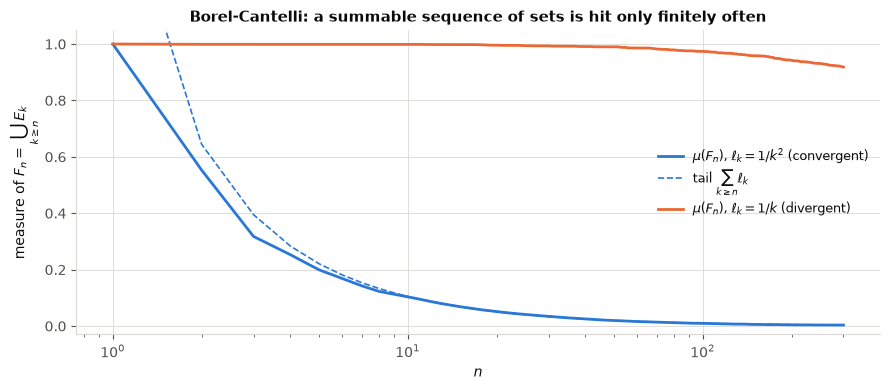

In [1]:

import numpy as np
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA, YELLOW, VIOLET, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#e34948"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "legend.frameon": False, "font.size": 10})

rng = np.random.default_rng(0)
K, grid = 4000, np.linspace(0, 1, 4001)
k = np.arange(1, K + 1)

def last_hit(lengths):
    """For each grid point x: the largest k <= K with x in E_k (0 if none)."""
    left = rng.uniform(0, 1 - np.minimum(lengths, 1), size=K)
    last = np.zeros(grid.size, dtype=int)
    for kk, (a, l) in enumerate(zip(left, lengths), start=1):
        last[(grid >= a) & (grid <= a + l)] = kk
    return last

fig, ax = plt.subplots(figsize=(9, 4))
for lengths, col, name in [(1.0 / k ** 2, BLUE, r"$\ell_k = 1/k^2$ (convergent)"),
                           (1.0 / k, ORANGE, r"$\ell_k = 1/k$ (divergent)")]:
    last = last_hit(lengths)
    n = np.arange(1, 301)
    mu_Fn = [(last >= nn).mean() for nn in n]          # x in F_n  <=>  last hit >= n
    ax.plot(n, mu_Fn, color=col, lw=2, label=r"$\mu(F_n)$, " + name)
    if col == BLUE:
        tail = np.cumsum(lengths[::-1])[::-1][:300]
        ax.plot(n, tail, color=BLUE, ls="--", lw=1.2, label=r"tail $\sum_{k \geq n} \ell_k$")
ax.set_xscale("log"); ax.set_ylim(-0.03, 1.05)
ax.set_xlabel("$n$"); ax.set_ylabel(r"measure of $F_n = \bigcup_{k \geq n} E_k$")
ax.set_title("Borel-Cantelli: a summable sequence of sets is hit only finitely often")
ax.legend(loc="center right", fontsize=9)
plt.tight_layout(); plt.show()